<a href="https://colab.research.google.com/github/huzaifamachinelearning/Virexo-internship/blob/main/Virexo_task_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Dataset Source

**Name:** titanic dataset

**Origin**:Titanic passenger dataset — originally compiled from Encyclopedia Titanica records, popularized through the Kaggle "Titanic: Machine Learning from Disaster" competition

**Accessed via:** Public GitHub mirror —
"https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
(used because it allows direct loading in Colab without Kaggle authentication)

**Size:** 891 rows × 12 columns

This dataset was not created by the author. It is used here for educational
purposes as part of the Virexo Innovations internship programme.

#**Overview**

In [ ]:
import pandas as pd
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv(url)
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


##explanation of Columns


| Variable | Definition                                 | Key                                                      |
|----------|--------------------------------------------|----------------------------------------------------------|
| survival | Survival                                   | 0 = No, 1 = Yes                                          |
| pclass   | Ticket class                               | 1 = 1st, 2 = 2nd, 3 = 3rd                                |
| sex      | Sex                                        |                                                          |
| Age      | Age in years                               |                                                          |
| sibsp    | # of siblings / spouses aboard the Titanic |                                                          |
| parch    | # of parents / children aboard the Titanic |                                                          |
| ticket   | Ticket number                              |                                                          |
| fare     | Passenger fare                             |                                                          |
| cabin    | Cabin number                               |                                                          |
| embarked | Port of Embarkation                        | C = Cherbourg, Q = Queenstown, S = Southampton           |

**pclass**: A proxy for socio-economic status (SES)
1st = Upper
2nd = Middle
3rd = Lower

**age**: Age is fractional if less than 1. If the age is estimated, is it in the form of xx.5

**sibsp**: The dataset defines family relations in this way...
Sibling = brother, sister, stepbrother, stepsister
Spouse = husband, wife (mistresses and fiancés were ignored)

**parch**: The dataset defines family relations in this way...
Parent = mother, father
Child = daughter, son, stepdaughter, stepson
Some children travelled only with a nanny, therefore parch=0 for them.

#**Exploration**

In [ ]:
titanic['Survived'].value_counts(normalize=True)

,proportion
Survived,
0,0.616162
1,0.383838


stratified splitting

In [ ]:
from sklearn.model_selection import train_test_split
titanic_train,titanic_test=train_test_split(
    titanic,
    test_size=0.2,
    stratify=titanic['Survived'],
    random_state=42)

In [ ]:
len(titanic_test),len(titanic_train)

(179, 712)

In [ ]:
titanic_explore=titanic_train.copy()

In [ ]:
titanic_explore.info()

<class 'pandas.core.frame.DataFrame'>
Index: 712 entries, 692 to 507
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  712 non-null    int64  
 1   Survived     712 non-null    int64  
 2   Pclass       712 non-null    int64  
 3   Name         712 non-null    object 
 4   Sex          712 non-null    object 
 5   Age          575 non-null    float64
 6   SibSp        712 non-null    int64  
 7   Parch        712 non-null    int64  
 8   Ticket       712 non-null    object 
 9   Fare         712 non-null    float64
 10  Cabin        160 non-null    object 
 11  Embarked     710 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 72.3+ KB


In [ ]:
# dropping PassengerId,Name,Ticket,Cabin and imputing null values for exploration puproses
num_attribs = ["Age", "SibSp", "Parch", "Fare"]
cat_attribs = ["Pclass", "Sex", "Embarked"]
for num_col in num_attribs:
  titanic_explore[num_col]=titanic_explore[num_col].fillna(titanic_explore[num_col].median())

for cat_col in cat_attribs:
  titanic_explore[cat_col]=titanic_explore[cat_col].fillna(titanic_explore[cat_col].mode()[0])

In [ ]:
titanic_explore=pd.DataFrame(titanic_explore,columns=num_attribs+cat_attribs+['Survived'])

In [ ]:
titanic_explore['Pclass']=titanic_explore['Pclass'].astype(object)

numerical columns

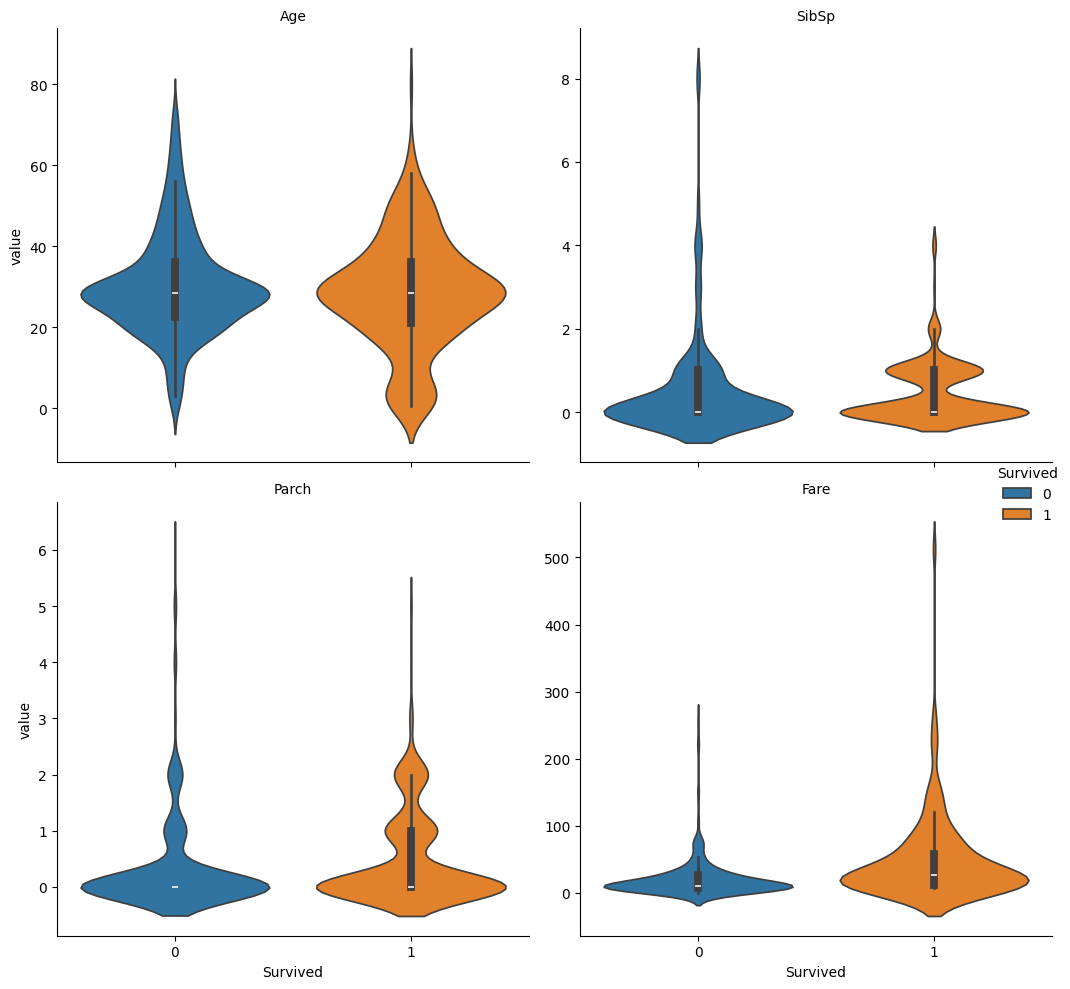

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
plot_df = titanic_explore[num_attribs+['Survived']].melt(
    id_vars='Survived',
    var_name='feature',
    value_name='value'
)

g = sns.catplot(
    data=plot_df,
    x='Survived',
    y='value',
    col='feature',
    col_wrap=2,
    kind='violin',
    hue='Survived',
    # medianprops={'color': 'black', 'linewidth': 2},

    sharey=False
)

g.set_titles('{col_name}')
plt.tight_layout()
plt.show()

categorical columns

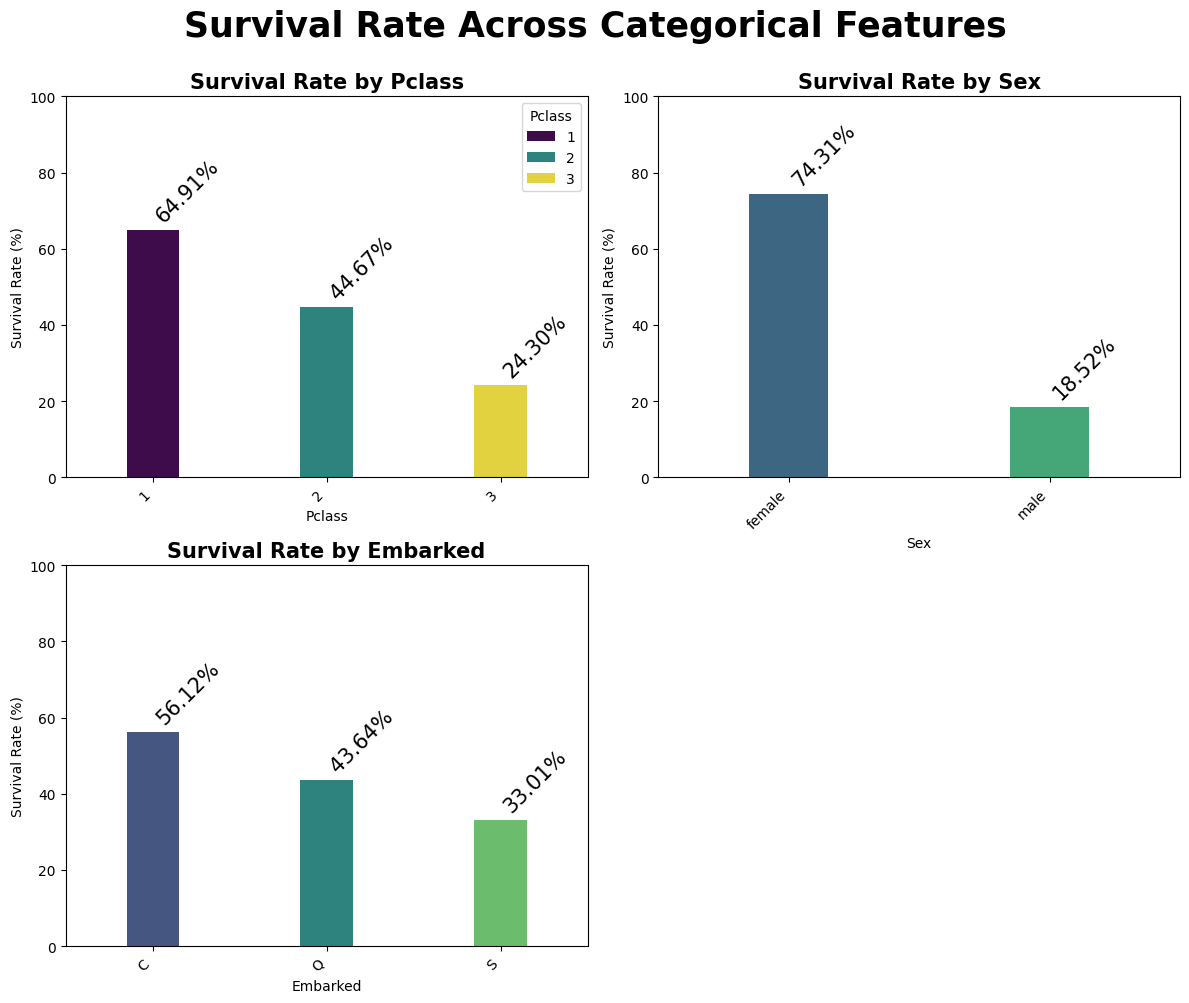

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

ncols = 2
nrows = math.ceil(len(cat_attribs) / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(12, 5 * nrows)
)

axes = axes.flatten()

for ax, col in zip(axes, cat_attribs):

    survival_rate = titanic_explore.groupby(col)['Survived'].mean().mul(100).sort_values(ascending=False).reset_index()

    sns.barplot(
        data=survival_rate,
        x=col,
        y='Survived',
        hue=col,
        palette='viridis',
        ax=ax,
        width=0.3,
    )

    ax.set_title(
        f'Survival Rate by {col}',
        fontsize=15,
        fontweight='bold'
    )

    ax.set_xlabel(col)
    ax.set_ylabel('Survival Rate (%)')

    ax.set_ylim(0, 100)

    for container in ax.containers:
        labels=ax.bar_label(
            container,
            fmt='%.2f%%',
            padding=3,
            fontsize=15
        )
        for label in labels:
          label.set_rotation(45)
          label.set_ha('left')
    ax.tick_params(axis='x',rotation=45)
    plt.setp(ax.get_xticklabels(), ha='right')

for ax in axes[len(cat_attribs):]:
    ax.remove()
fig.suptitle(
    'Survival Rate Across Categorical Features',
    fontsize=25,
    fontweight='bold',
    y=0.999
)
plt.tight_layout()
plt.show()

#**Preprocessing**

In [ ]:
X_train,y_train=titanic_train.drop('Survived',axis=1),titanic_train['Survived'].copy()

In [ ]:
from sklearn.pipeline import make_pipeline,Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
def num_pipeline():
  return make_pipeline(
      SimpleImputer(strategy='median'),
      StandardScaler(),

  )

def cat_pipeline():
  return make_pipeline(
      SimpleImputer(strategy='most_frequent'),
      OneHotEncoder(sparse_output=False,handle_unknown='ignore')
  )

preprocessing_pipeline=ColumnTransformer([
    ('num_pipeline',num_pipeline(),num_attribs),
    ('cat_pipeline',cat_pipeline(),cat_attribs)
])

In [ ]:
X_transformed=preprocessing_pipeline.fit_transform(X_train)

In [ ]:
import numpy as np
np.isnan(X_transformed).any()

np.False_

##Helper Functions

### evaluation function

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold


from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# if train=False gets clean scores for each of the instances
# and calcualte metrics. Otherwise trains the model and get scores on
# on the same dataset. Useful for determining over fitting
def evaluate(name, model, X, y, method='predict_proba', threshold=0.5,train=False, cv=3):
    model=clone(model)



    if train:
      model.fit(X,y)
      raw = model.predict_proba(X) if method == 'predict_proba' else model.decision_function(X)
    else:
      raw = cross_val_predict(model, X, y, cv=cv, method=method)
    scores = raw[:, 1] if method == 'predict_proba' else raw
    pred = scores >= threshold
    acc = accuracy_score(y, pred)
    prec_score=precision_score(y, pred, zero_division=0)
    rec_score=recall_score(y, pred)
    f1=f1_score(y, pred)
    ap, auc = average_precision_score(y, scores), roc_auc_score(y, scores)

    return {'name': name,
            'accuracy': acc,
            'ap': ap,
            'roc_auc': auc,
            'precision_score':prec_score,
            'recall_score':rec_score,
            'f1_score':f1,
            'confusion_matrix':confusion_matrix(y, pred)
            }

###model_comparison function

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns



def plot_model_performance(
    model1_name, model1,
    model2_name, model2,
    X, y,
    eval_kwargs,
    metrics_to_plot=None
):
    if metrics_to_plot is None:
        metrics_to_plot = [
            'accuracy',
            'ap',
            'roc_auc',
            'precision_score',
            'recall_score',
            'f1_score'
        ]


    results1 = evaluate(
        model1_name, model1, X, y, **eval_kwargs[0]
    )


    results2 = evaluate(
        model2_name, model2, X, y, **eval_kwargs[1]
    )

    # Create plotting DataFrame
    data = []

    for metric in metrics_to_plot:
        if metric in results1 and metric in results2:
            data.append({
                'Metric': metric,
                'Model': model1_name,
                'Score': results1[metric] * 100
            })

            data.append({
                'Metric': metric,
                'Model': model2_name,
                'Score': results2[metric] * 100
            })

    if not data:
        print("No common plotable metrics found.")
        return

    df_results = pd.DataFrame(data)


    metric_labels = {
        'accuracy': 'Accuracy',
        'ap': 'Average Precision',
        'roc_auc': 'ROC-AUC',
        'precision_score': 'Precision',
        'recall_score': 'Recall',
        'f1_score': 'F1 Score'
    }

    df_results['Metric'] = df_results['Metric'].map(metric_labels)

    # Plot
    fig, ax = plt.subplots(figsize=(12, 6))

    sns.barplot(
        data=df_results,
        x='Metric',
        y='Score',
        hue='Model',
        ax=ax,
        palette='viridis',
        width=0.7
    )

    # Title
    data_type = "Train" if eval_kwargs[0].get('train') else "Cross-Validated"

    ax.set_title(
        f'Model Performance Comparison — {data_type} Data',
        fontsize=17,
        fontweight='bold',
        pad=18
    )

    ax.set_xlabel('')
    ax.set_ylabel('Score (%)', fontsize=12)

    # Y-axis
    ax.set_ylim(0, 105)
    ax.set_yticks(range(0, 101, 10))
    ax.tick_params(axis='y', labelsize=10)

    # X-axis
    ax.tick_params(axis='x', labelsize=11)
    plt.xticks(rotation=0)

    # Horizontal grid
    ax.grid(
        axis='y',
        linestyle='--',
        alpha=0.3
    )
    ax.set_axisbelow(True)

    # Remove unnecessary borders
    sns.despine(ax=ax, left=True, bottom=True)

    # Add values above bars
    for container in ax.containers:
        ax.bar_label(
            container,
            fmt='%.1f%%',
            padding=4,
            fontsize=10,
            fontweight='bold'
        )

    # Legend
    ax.legend(
        title='Model',
        title_fontsize=11,
        fontsize=10,
        loc='upper right',
        frameon=False
    )

    plt.tight_layout()
    plt.show()







### model overfitting comparison function

the function calculates overfitting as the  ratio of the decrease  in  a metric after cross validation to the metric's value obtained when trained and evaluated on the training set

In [ ]:
def plot_model_performance_overfit(
    model1_name, model1,
    model2_name, model2,
    X, y,
    eval_kwargs_train, # List of 2 dicts, for model1_train and model2_train
    eval_kwargs_cv,    # List of 2 dicts, for model1_cv and model2_cv
    metrics_to_plot=None
):



    if metrics_to_plot is None:
        metrics_to_plot = [
            'accuracy',
            'ap',
            'roc_auc',
            'precision_score',
            'recall_score',
            'f1_score'
        ]


    results1_train = evaluate(model1_name + ' (Train)', model1, X, y, **eval_kwargs_train[0])


    results2_train = evaluate(model2_name + ' (Train)', model2, X, y, **eval_kwargs_train[1])


    results1_cv = evaluate(model1_name + ' (CV)', model1, X, y, **eval_kwargs_cv[0])


    results2_cv = evaluate(model2_name + ' (CV)', model2, X, y, **eval_kwargs_cv[1])

    data = []
    metric_labels = {
        'accuracy': 'Accuracy',
        'ap': 'Average Precision',
        'roc_auc': 'ROC-AUC',
        'precision_score': 'Precision',
        'recall_score': 'Recall',
        'f1_score': 'F1 Score'
    }

    for metric in metrics_to_plot:
        if metric in results1_train and metric in results2_train and \
           metric in results1_cv and metric in results2_cv:

            # Calculate percentage difference for model 1
            cv_score_1 = results1_cv[metric]
            if cv_score_1 != 0:
                diff_model_1 = ((results1_train[metric] -cv_score_1) / cv_score_1) * 100
            else:
                diff_model_1 = float('nan') # Handle division by zero

            data.append({
                'Metric': metric,
                'Model': model1_name,
                'Percentage Difference': diff_model_1
            })

            # Calculate percentage difference for model_2
            cv_score_2 = results2_cv[metric]
            if cv_score_2 != 0:
                diff_model_2 = ((results2_train[metric] - cv_score_2) / cv_score_2) * 100
            else:
                diff_model_2= float('nan') # Handle division by zero

            data.append({
                'Metric': metric,
                'Model': model2_name,
                'Percentage Difference': diff_model_2
            })

    if not data:
        print("No common plotable metrics found or specified.")
        return

    df_results = pd.DataFrame(data)
    df_results['Metric'] = df_results['Metric'].map(metric_labels)

    fig, ax = plt.subplots(figsize=(12, 6))
    sns.barplot(
        data=df_results,
        x='Metric',
        y='Percentage Difference',
        hue='Model',
        ax=ax,
        palette='viridis',
        width=0.7
    )

    ax.set_title(
        f'Overfitting comparison: {model2_name} vs {model1_name}',
        fontsize=17,
        fontweight='bold',
        pad=18
    )
    ax.set_xlabel('')
    ax.set_ylabel('Percentage Change (%)', fontsize=12)

    # Dynamic y-axis limits to accommodate positive and negative changes
    max_val = df_results['Percentage Difference'].abs().max()
    if pd.isna(max_val): # Handle case where all diffs are NaN
        ax.set_ylim(-10, 10)
    else:
        margin = max(5, max_val * 0.1)
        ax.set_ylim(-max_val - margin, max_val + margin)

    ax.axhline(0, color='grey', linestyle='--', linewidth=0.8) # Add a zero line

    ax.tick_params(axis='y', labelsize=10)
    ax.tick_params(axis='x', labelsize=11)
    plt.xticks(rotation=0)

    ax.grid(
        axis='y',
        linestyle='--',
        alpha=0.3
    )
    ax.set_axisbelow(True)

    sns.despine(ax=ax, left=True, bottom=True)

    for container in ax.containers:
        ax.bar_label(
            container,
            fmt='%.1f%%',
            padding=4,
            fontsize=10,
            fontweight='bold'
        )

    ax.legend(
        title='Model',
        title_fontsize=11,
        fontsize=10,
        loc='best',
        frameon=False
    )

    plt.tight_layout()
    plt.show()





because the dataset is small and cross validation folds would be small further we do stratify splits in cross validations

In [ ]:
stratified_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# **Training**
we try two models random forest regressor and svm classifiers

61 percent is the accuracy we have to beat

In [ ]:
from sklearn.dummy import DummyClassifier
dummy_clf=DummyClassifier()
dummy_clf.fit(X_train,y_train)
pred=dummy_clf.predict(y_train)
accuracy_score(y_train,pred)

0.6165730337078652

**trying out random forest**

In [ ]:
from sklearn.ensemble import RandomForestClassifier

forest_pipeline = Pipeline(
    [
        ('preprocessing', preprocessing_pipeline),
        ('random_forest_model', RandomForestClassifier(max_leaf_nodes=12,random_state=42))
    ]
)
evaluate('random_forest-train', forest_pipeline, X_train, y_train,threshold=0.5, train=True, cv=stratified_cv)

{'name': 'random_forest-train',
 'accuracy': 0.8497191011235955,
 'ap': np.float64(0.8830987390444137),
 'roc_auc': np.float64(0.8980700393001076),
 'precision_score': 0.9068627450980392,
 'recall_score': 0.6776556776556777,
 'f1_score': 0.7756813417190775,
 'confusion_matrix': array([[420,  19],
        [ 88, 185]])}

In [ ]:
evaluate('random_forest-test', forest_pipeline, X_train, y_train,threshold=0.5, train=False, cv=stratified_cv)

{'name': 'random_forest-test',
 'accuracy': 0.8188202247191011,
 'ap': np.float64(0.8399731506118971),
 'roc_auc': np.float64(0.8658831677054911),
 'precision_score': 0.8428571428571429,
 'recall_score': 0.6483516483516484,
 'f1_score': 0.7329192546583851,
 'confusion_matrix': array([[406,  33],
        [ 96, 177]])}

**trying out svm**

In [ ]:
from sklearn.svm import SVC

svm_pipeline = Pipeline(
    [
        ('preprocessing', preprocessing_pipeline),
        ('svm_model', SVC(kernel='rbf', random_state=42,))
    ]
)
evaluate('svm-train', svm_pipeline, X_train, y_train,threshold=0,method='decision_function', train=True, cv=stratified_cv)

{'name': 'svm-train',
 'accuracy': 0.8426966292134831,
 'ap': np.float64(0.8576532700155192),
 'roc_auc': np.float64(0.8853371381845185),
 'precision_score': 0.8454935622317596,
 'recall_score': 0.7216117216117216,
 'f1_score': 0.7786561264822134,
 'confusion_matrix': array([[403,  36],
        [ 76, 197]])}

In [ ]:
evaluate('svm-test', svm_pipeline, X_train, y_train,threshold=0, method='decision_function',train=False, cv=stratified_cv)

{'name': 'svm-test',
 'accuracy': 0.8174157303370787,
 'ap': np.float64(0.8076246364017489),
 'roc_auc': np.float64(0.8491159561774595),
 'precision_score': 0.8016877637130801,
 'recall_score': 0.6959706959706959,
 'f1_score': 0.7450980392156863,
 'confusion_matrix': array([[392,  47],
        [ 83, 190]])}

**comparison of models visulaized**

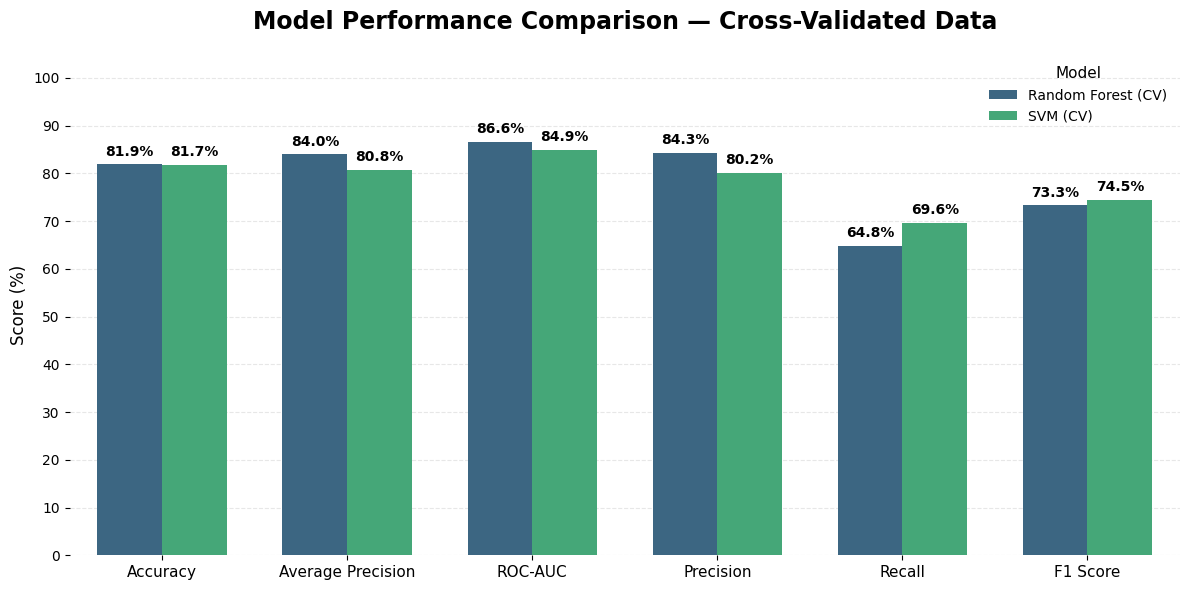

In [ ]:
# 2. Evaluate on cross-validated (test) data
plot_model_performance(
    'Random Forest (CV)',
    forest_pipeline,
    'SVM (CV)',
    svm_pipeline,
    X_train, y_train,
    eval_kwargs=[
        {'train': False, 'cv': stratified_cv, 'method': 'predict_proba','threshold':0.5},
        {'train': False, 'cv': stratified_cv, 'method': 'decision_function','threshold':0}
    ]
)



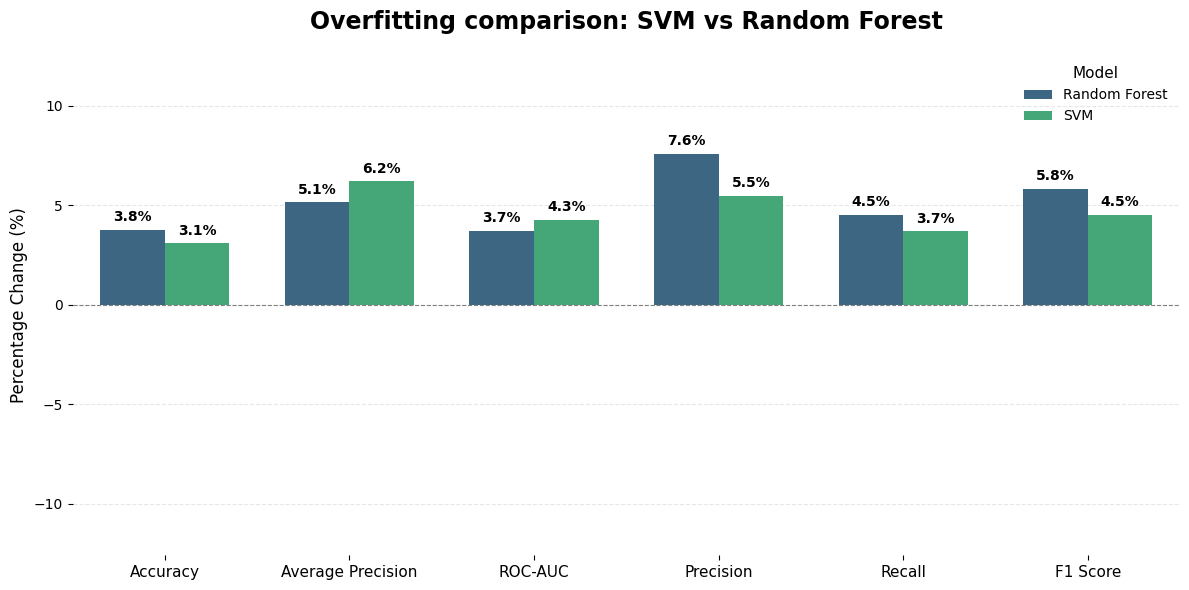

In [ ]:
plot_model_performance_overfit(
    'Random Forest', forest_pipeline,
    'SVM', svm_pipeline,
    X_train, y_train,
    eval_kwargs_train=[
        {'train': True, 'cv': stratified_cv, 'method': 'predict_proba','threshold':0.5},
        {'train': True, 'cv': stratified_cv, 'method': 'decision_function','threshold':0}
    ],
    eval_kwargs_cv=[
        {'train': False, 'cv': stratified_cv, 'method': 'predict_proba','threshold':0.5},
        {'train': False, 'cv': stratified_cv, 'method': 'decision_function','threshold':0}
    ]
)

##fine tuning
we fine tune svm  and random forest. As the LinearSVC class has more option available for fine tuning for linear svm than svc we fine tune it separately and it turns out to be the winner

 **Fine-tuning the SVC Model with RandomizedSearchCV**

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, loguniform
from sklearn.svm import LinearSVC
LinearSVC()

SVC()

param_dist =[ {
    'svm_model__C':loguniform(0.1, 100),

    'svm_model__degree':[1,2,3],
    'svm_model__gamma':loguniform(0.001, 10),
    'svm_model__kernel': ['rbf', 'poly',]
}
]


random_search_svm = RandomizedSearchCV(
    svm_pipeline,
    param_distributions=param_dist,
    n_iter=10,
    cv=stratified_cv,
    scoring='roc_auc',
    random_state=42,
    return_train_score=True,
    n_jobs=-1,
    verbose=2
)



random_search_svm.fit(X_train, y_train)
print("RandomizedSearchCV for SVM completed.")


print(f"Best parameters for SVM: {random_search_svm.best_params_}")
print(f"Best ROC AUC score for SVM: {random_search_svm.best_score_:.4f}")



Fitting 5 folds for each of 10 candidates, totalling 50 fits
RandomizedSearchCV for SVM completed.
Best parameters for SVM: {'svm_model__C': np.float64(0.11727009450102248), 'svm_model__degree': 3, 'svm_model__gamma': np.float64(0.2801635158716261), 'svm_model__kernel': 'poly'}
Best ROC AUC score for SVM: 0.8589
Best ROC AUC train score for SVM: 0.8589


In [ ]:
svm_results=pd.DataFrame(random_search_svm.cv_results_)
svm_results['mean_train_score'][random_search_svm.best_index_]

np.float64(0.8987077456866898)

**Fine-tuning the LinearSVC Model with RandomizedSearchCV**

In [ ]:
from sklearn.svm import LinearSVC
from scipy.stats import loguniform


linear_svc_pipeline = Pipeline(
    [
        ('preprocessing', preprocessing_pipeline),
        ('linear_svc_model', LinearSVC( random_state=42, dual=False)) # Set dual=False for n_samples > n_features
    ]
)


param_dist_linear_svc = {
    'linear_svc_model__C': loguniform(0.01, 100),
    'linear_svc_model__penalty': ['l1','l2'],
    'linear_svc_model__loss': [ 'squared_hinge'],
    'linear_svc_model__intercept_scaling':[1,2,3,4,5],
    'linear_svc_model__fit_intercept':[True,False]
}





random_search_linear_svc = RandomizedSearchCV(
    linear_svc_pipeline,
    param_distributions=param_dist_linear_svc,
    n_iter=10,
    cv=stratified_cv,
    scoring='roc_auc',
    random_state=42,
    return_train_score=True,
    n_jobs=-1,
    error_score='raise',
    verbose=2
)


random_search_linear_svc.fit(X_train, y_train)



print(f"Best parameters for LinearSVC: {random_search_linear_svc.best_params_}")
print(f"Best ROC AUC score for LinearSVC: {random_search_linear_svc.best_score_*100:.4f}")

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters for LinearSVC: {'linear_svc_model__C': np.float64(0.037279259033769864), 'linear_svc_model__fit_intercept': True, 'linear_svc_model__intercept_scaling': 5, 'linear_svc_model__loss': 'squared_hinge', 'linear_svc_model__penalty': 'l2'}
Best ROC AUC score for LinearSVC: 85.4476


In [ ]:
linear_svc_results=pd.DataFrame(random_search_linear_svc.cv_results_)
linear_svc_results['mean_train_score'][random_search_linear_svc.best_index_]

np.float64(0.8596992630369295)

**Fine-tuning the RandomForestClassifier Model with RandomizedSearchCV**

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
from sklearn.ensemble import RandomForestClassifier

RandomForestClassifier()


param_dist_rf = {
    'random_forest_model__n_estimators': randint(low=50, high=400),
    'random_forest_model__max_depth': randint(low=5, high=50),
    'random_forest_model__min_samples_split': randint(low=2, high=20),
    'random_forest_model__min_samples_leaf': randint(low=1, high=10),
    'random_forest_model__bootstrap': [True, False]

}


random_search_rf = RandomizedSearchCV(
    forest_pipeline,
    param_distributions=param_dist_rf,
    n_iter=10,
    cv=stratified_cv,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1,
    return_train_score=True,
    verbose=2

)



random_search_rf.fit(X_train, y_train)



print(f"Best parameters for RandomForestClassifier: {random_search_rf.best_params_}")
print(f"Best ROC AUC score for RandomForestClassifier (CV): {random_search_rf.best_score_*100:.4f}")
print(f"Best ROC AUC score for RandomForestClassifier (Train): {random_search_rf.cv_results_['mean_train_score'][random_search_rf.best_index_]:.4f}")

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters for RandomForestClassifier: {'random_forest_model__bootstrap': False, 'random_forest_model__max_depth': 25, 'random_forest_model__min_samples_leaf': 1, 'random_forest_model__min_samples_split': 13, 'random_forest_model__n_estimators': 363}
Best ROC AUC score for RandomForestClassifier (CV): 87.1119
Best ROC AUC score for RandomForestClassifier (Train): 0.9056


#**evaluation**

random forest looks slightly  better overall but this difference could be statistically unsignificant. however it does have to have some advantage in precison. We would have to investigate further

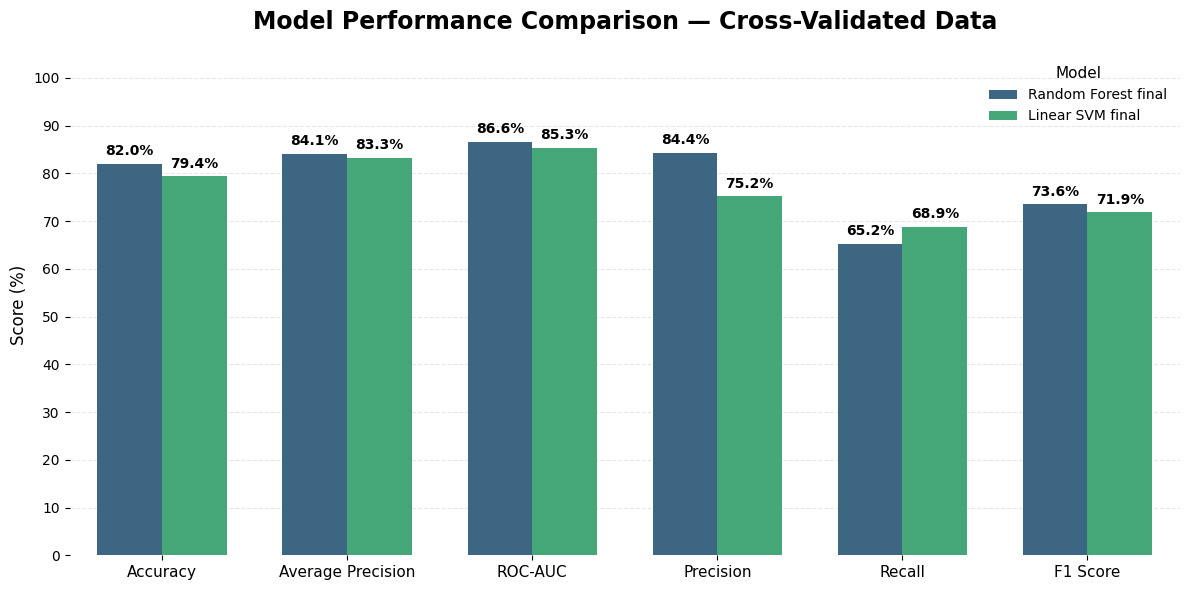

In [ ]:
plot_model_performance(
    'Random Forest final',
    random_search_rf.best_estimator_
    ,
    'Linear SVM final',
    random_search_linear_svc.best_estimator_,
    X_train, y_train,
    eval_kwargs=[
        {'train': False, 'cv': stratified_cv, 'method': 'predict_proba','threshold':0.5},
        {'train': False, 'cv': stratified_cv, 'method': 'decision_function','threshold':0}
    ]
)

## Overfitting
 random forest overfits badly as compared to linear svc and that is  after finetuning over regularization parameters

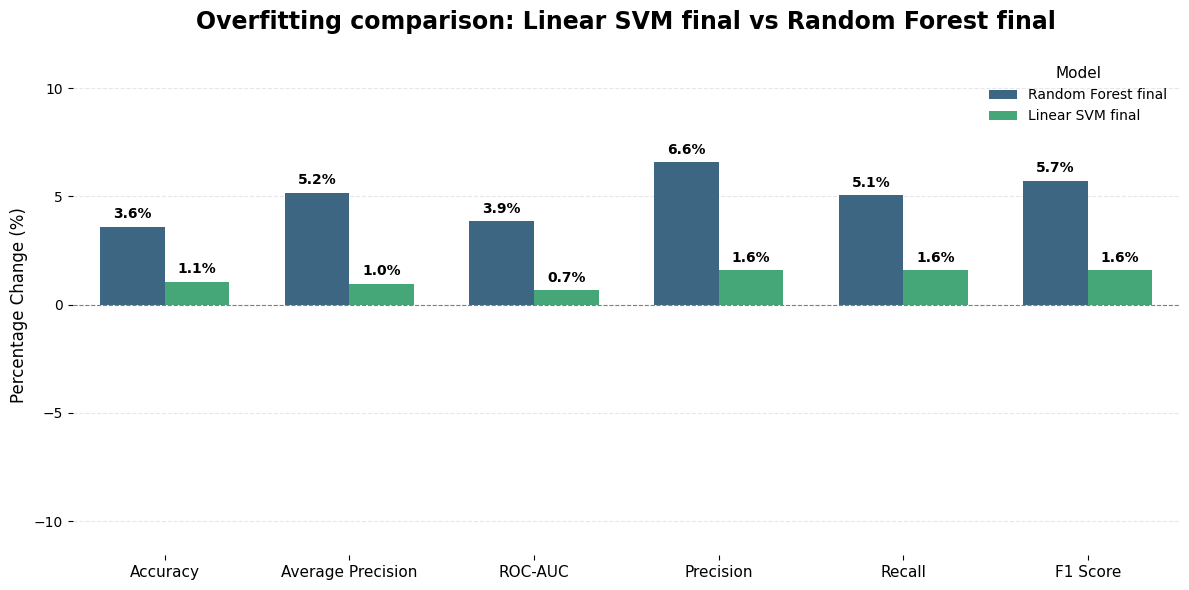

In [ ]:
plot_model_performance_overfit(
    'Random Forest final',
    random_search_rf.best_estimator_,

    'Linear SVM final',
    random_search_linear_svc.best_estimator_,
    X_train, y_train,
    eval_kwargs_train=[
        {'train': True, 'cv': stratified_cv, 'method': 'predict_proba','threshold':0.5},
        {'train': True, 'cv': stratified_cv, 'method': 'decision_function','threshold':0}
    ],
    eval_kwargs_cv=[
        {'train': False, 'cv': stratified_cv, 'method': 'predict_proba','threshold':0.5},
        {'train': False, 'cv': stratified_cv, 'method': 'decision_function','threshold':0}
    ]
)

## Confusion matrix
the random_forest has a smaller false positive rate consistent with slightly better precison rate

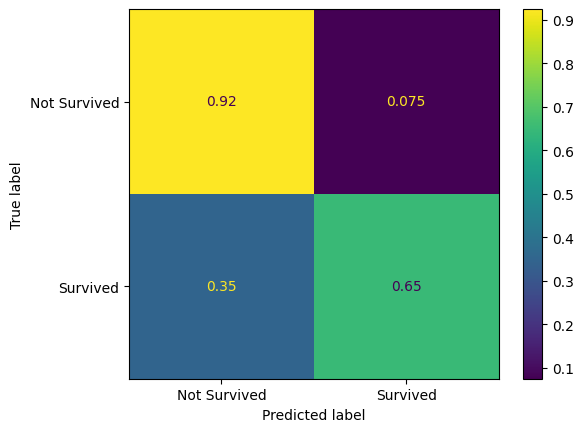

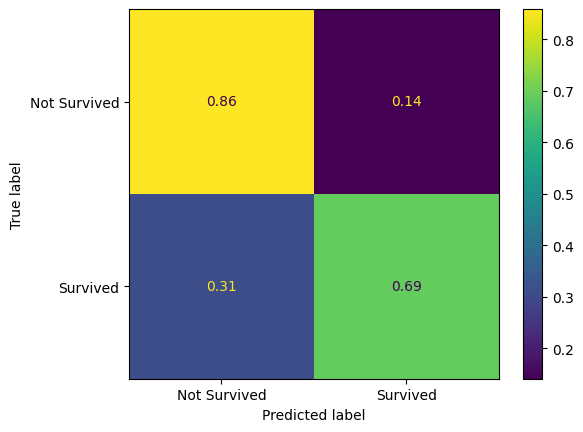

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
rf_best=clone(random_search_rf.best_estimator_)
svc_best=clone(random_search_linear_svc.best_estimator_)

rf_proba= cross_val_predict(rf_best, X_train, y_train, cv=stratified_cv, method='predict_proba')[:,1]
svc_scores= cross_val_predict(svc_best, X_train, y_train, cv=stratified_cv, method='decision_function')

ConfusionMatrixDisplay.from_predictions(y_train,rf_proba>=0.5,normalize='true',display_labels=["Not Survived", "Survived"])
ConfusionMatrixDisplay.from_predictions(y_train,svc_scores>=0,normalize='true',display_labels=["Not Survived", "Survived"])



##meauring preciseness of random forest advantage in accuracy

the confidence intervals definitely overlap so the advantage is not statistically significant atleast in the case of accuracy which is a pretty good meaure for this dataset.


In [ ]:
rf_accuracy=accuracy_score(y_train,(rf_proba>=0.5).astype(int))
svc_accuracy=accuracy_score(y_train,(svc_scores>=0).astype(int))


In [ ]:
from scipy import stats


def accuracy(correct):
    return np.mean(correct)
def get_confidence_interval(y,pred,confidence):

  correct = (pred == y).astype(int)

  boot_result = stats.bootstrap(
      [correct],
      accuracy,
      confidence_level=confidence,
      random_state=42
  )

  return boot_result.confidence_interval

rf_low,rf_high=get_confidence_interval(y_train,(rf_proba>=0.5).astype(int),0.95)
svc_low,svc_high=get_confidence_interval(y_train,(svc_scores>=0).astype(int),0.95)



print(f'({rf_low},{rf_accuracy},{rf_high})')
print(f'({svc_low},{svc_accuracy},{svc_high})')



(0.7907303370786517,0.8202247191011236,0.8469101123595506)
(0.7626404494382022,0.7935393258426966,0.8216292134831461)


## Precision-Recall Curve
curves of both models have the same shape. The one for linearsvc looks slightly low signaling a bit low precision overall (not just at the default threshold),but again this could be statistically insignificant

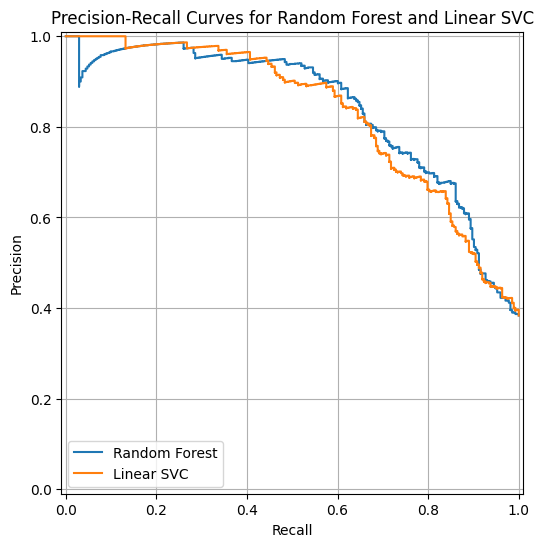

In [ ]:
from sklearn.metrics import PrecisionRecallDisplay, precision_recall_curve
import matplotlib.pyplot as plt


prec_rf, rec_rf, _ = precision_recall_curve(y_train, rf_proba)

prec_svc, rec_svc, _ = precision_recall_curve(y_train, svc_scores)


fig, ax = plt.subplots(figsize=(8, 6))


PrecisionRecallDisplay(precision=prec_rf, recall=rec_rf, estimator_name='Random Forest').plot(ax=ax)


PrecisionRecallDisplay(precision=prec_svc, recall=rec_svc, estimator_name='Linear SVC').plot(ax=ax)

ax.set_title('Precision-Recall Curves for Random Forest and Linear SVC')
ax.legend(loc='lower left')
plt.grid(True)
plt.show()

## Learning Curve
learning curves further confirm that the random forest model is overfitting.The curve for LinearSVC indicates that it does not overfit even on small sized training sets.

In [ ]:
from sklearn.model_selection import learning_curve
import matplotlib.pyplot as plt
import numpy as np

def plot_learning_curve(estimator, title, X, y, axes=None, ylim=None, cv=None, n_jobs=None, train_sizes=np.linspace(.1, 1.0, 5)):



    fig, ax = plt.subplots(figsize=(10, 6))

    ax.set_title(title)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.set_xlabel("Training examples")
    ax.set_ylabel("Score")

    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, cv=cv, n_jobs=n_jobs, train_sizes=train_sizes, scoring='roc_auc')
    train_scores_mean = np.mean(train_scores, axis=1)

    test_scores_mean = np.mean(test_scores, axis=1)


    # Plot training curve
    ax.grid()

    ax.plot(train_sizes, train_scores_mean, 'o-', color="r",
             label="Training score")

    # Plot cross-validation curve

    ax.plot(train_sizes, test_scores_mean, 'o-', color="g",
             label="Cross-validation score")

    ax.legend(loc="best")


    return fig, ax


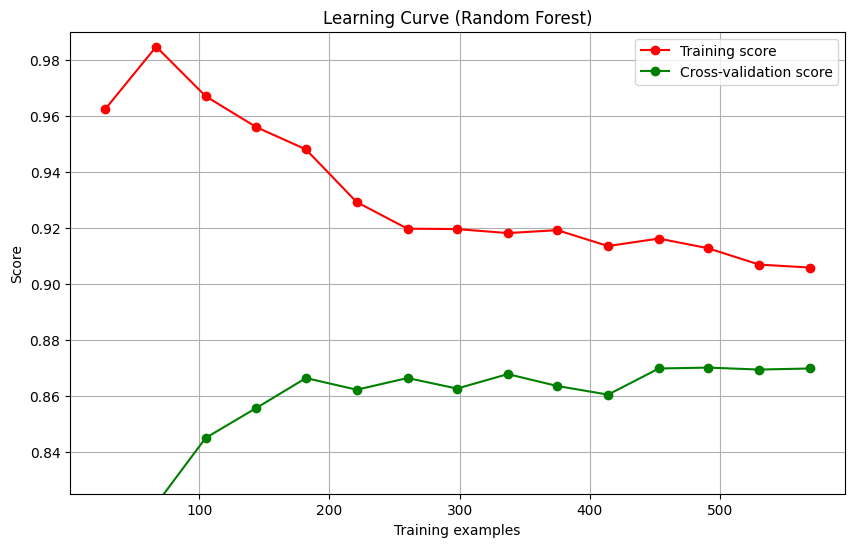

In [ ]:


plot_learning_curve(rf_best, "Learning Curve (Random Forest)", X_train, y_train,ylim=(0.825,0.990),train_sizes=np.linspace(0.05,1,15), cv=stratified_cv, n_jobs=-1)
plt.show()

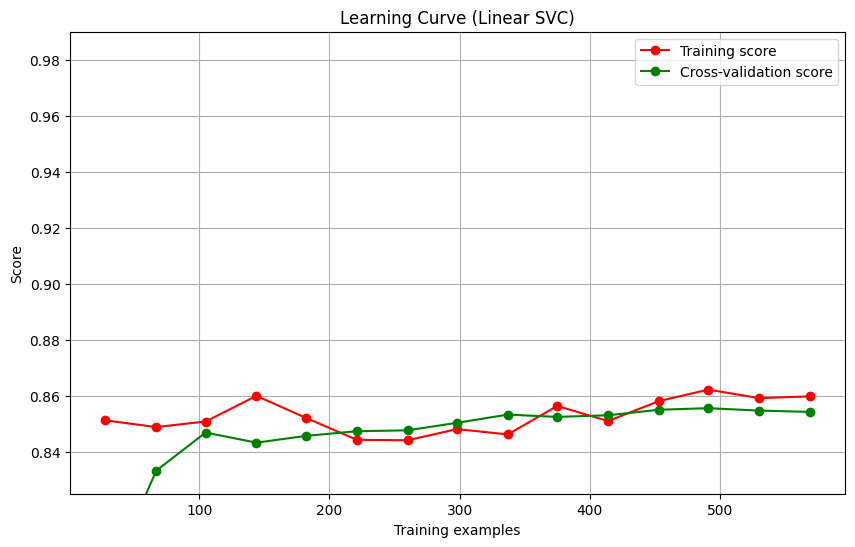

In [ ]:


plot_learning_curve(svc_best, "Learning Curve (Linear SVC)", X_train, y_train,ylim=(0.825,0.99),train_sizes=np.linspace(0.05,1,15), cv=stratified_cv, n_jobs=-1)
plt.show()

## Why did I chose linear svc model

**we chose linear svc model, because**
1. The insample values for svm metrics are about 1.6% more than their cross validation value, at maximum. While the insample values for random forest are 3.6% of their crossvalidation counterparts at minimum. The overfitting claim is further confirmed by the learning curves

2. random forest only has a slight advantage over svc model in most of metrics and we saw that in case of accuracy the advantage was statistically unsignificant.
3. Where the advantage may look like it is something statistically significant, it is only a little better(precision)

**limitations of our chosen model**
1. The data is small so the model may have bias and with more data the model's assumpitons may fail to hold.

2. As the focus of this assignment was model comparison we have not paid much attention to feature engineering which could be useful because our accuracy is 79%(using cross validation)

3. We have not paid much attention to the thought that survival or non-survival of persons may be correlated with each other. In other words we have assumed that the rows are independent which is likely not the case



#**Predictions**

1. our model gives slightly better performance on the test set but we have to take it with a grain of salt because the test set is small.

2. Our model predicts that Mr Calus Peter Hansen did not survive and indeed he did not.


In [ ]:
X_test,y_test=titanic_test.drop('Survived',axis=1),titanic_test['Survived'].copy()
pred=random_search_linear_svc.best_estimator_.predict(X_test)
accuracy_score(y_test,pred)

0.8044692737430168

In [ ]:
X_test.iloc[[3]]

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
860,861,3,"Hansen, Mr. Claus Peter",male,41.0,2,0,350026,14.1083,NaN,S


In [ ]:
random_search_linear_svc.best_estimator_.predict(X_test.iloc[[3]]),y_test.iloc[3]

(array([0]), np.int64(0))